In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
from sklearn.metrics import mean_absolute_error 

In [3]:
with open("MNISTsmall.p", "rb") as data_file:
    D = pickle.load(data_file)
"""
with open("A50746_Ficha2_Respostas.p", "rb") as respostas_file:
    respostas = pickle.load(respostas_file)
"""

'\nwith open("A50746_Ficha2_Respostas.p", "rb") as respostas_file:\n    respostas = pickle.load(respostas_file)\n'

In [4]:
D

{'data': array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], dtype=uint8),
 'target': array([0, 0, 0, ..., 9, 9, 9], dtype=uint8),
 'DESCR': 'A subset of the MNIST database of handwritten digits.\nThe original database was developed by Yann LeCun, Corinna Cortes, and Chris Burges. \nFor more information check: http://http://yann.lecun.com/exdb/mnist/.\n\nThe MNISTsmall dataset is composed  of 15000 images of 28x28 pixels consisting of handwritten digits 0 to 9.\nThe first 10000 correspond the the training set and the last 5000 to the test data (also accessible via "foldTrain" variable).\nThe data is packed in a dictionary-type object (actually a utils.Bunch object of sklearn):\ndata   --> dxN where N=15000 (the number of examples) and d=784=28x28 (data dimension)\ntarget --> N   labels from 0 to 9 (examples\' classes)\n',
 'targe

In [5]:
D.keys()

dict_keys(['data', 'target', 'DESCR', 'target_names', 'foldTrain'])

In [6]:
X = D['data']
y = D['target']
yname = D['target_names']
foldtrain = D['foldTrain']

print("X shape:", X.shape)
print("Y shape:", y.shape)
print("foldtrain", foldtrain.shape)

print(yname)
print(np.unique(y))

X shape: (784, 15000)
Y shape: (15000,)
foldtrain (15000,)
['0: zero', '1: one', '2: two', '3: three', '4: four', '5: five', '6: six', '7: seven', '8: eight', '9: nine']
[0 1 2 3 4 5 6 7 8 9]


# 1.

#### Considere os 372 primeiros exemplos do conjunto de treino do digito “3”

In [7]:
# Filtrar os índices dos primeiros 372 exemplos do dígito "3"
indices_3 = np.where(y == 3)[0][:372]

# Selecionar as colunas correspondentes ao dígito "3"
X_3 = X[:, indices_3]

# a.

##### Para esta alinea arredonde os valores pedidos a 0 casas decimais. Considere o 189º digito da matriz de dados. Pretende-se projetar e reconstruir este digito usando um numero minimo de componentes principais tal que os dados projetados tenham 57% da variancia total dos dados originais. O erro absoluto médio entre o digito original e o reconstruido é:

In [14]:
# Selecionar o 189º dígito
seila = X_3[:, 188]

# Calcula a matriz de covariância dos dados X_3
cov = np.cov(X_3)

# Calcula os autovalores (u) e autovetores (W) da matriz de covariância
u, W = np.linalg.eig(cov)

# Garante que os autovalores e autovetores sejam números reais
u = u.real
W = W.real

# Ordena os autovalores em ordem decrescente e rearranja os autovetores de acordo
idx = np.argsort(-u)
u = u[idx]
W = W[:, idx]

# Normaliza os autovalores para calcular a variância explicada (soma dos autovalores = 1)
un = u / np.sum(u)

# Calcula a variância explicada acumulada
L = np.cumsum(un)

# Determina o número de componentes principais necessários para ter 57% da variância explicada
ncompo = np.sum(L <= 0.57)

# Seleciona os primeiros ncompo autovetores para formar a matriz de projeção W2
W2 = W[:, :ncompo]

# Projeta os dados originais X_3 para a subespacial de componentes principais usando W2
Xp = np.dot(W2.T, X_3)

# Reconstrói os dados a partir da projeção para obter uma aproximação dos dados originais
Xr = np.dot(W2, Xp)

# Seleciona o 189º dígito da matriz de dados reconstruídos
outro_seila = Xr[:, 188]

resposta = mean_absolute_error(seila, outro_seila)

print(f"Resposta: {np.round(resposta, 0)}")


Resposta: 29.0


# b. 

#### Considere que se estima a matriz de covariancia deste conjunto
##### i. A dimensão da matriz é 372 × 372.
##### ii. O determinante da matriz de convariancia é igual a 0.

In [16]:
cov_matrix = np.cov(X_3)

print("Resposta i:", cov_matrix.shape)

# Calcular o determinante da matriz de covariância
det_cov_matrix = np.linalg.det(cov_matrix)
print("Resposta ii:", det_cov_matrix)

Resposta i: (784, 784)
Resposta ii: 0.0


# c.

#### Pretende-se visualizar os digitos deste conjunto e os vetores prorpios da matriz de covariancia dos dados

##### i. A figura de cima ́e a imagem invertida do 267º digito do conjunto.
##### ii. A figura de baixo e a imagem (ou a imagem invertida) do 16º vetor proprio da matriz de covariancia dos dados.

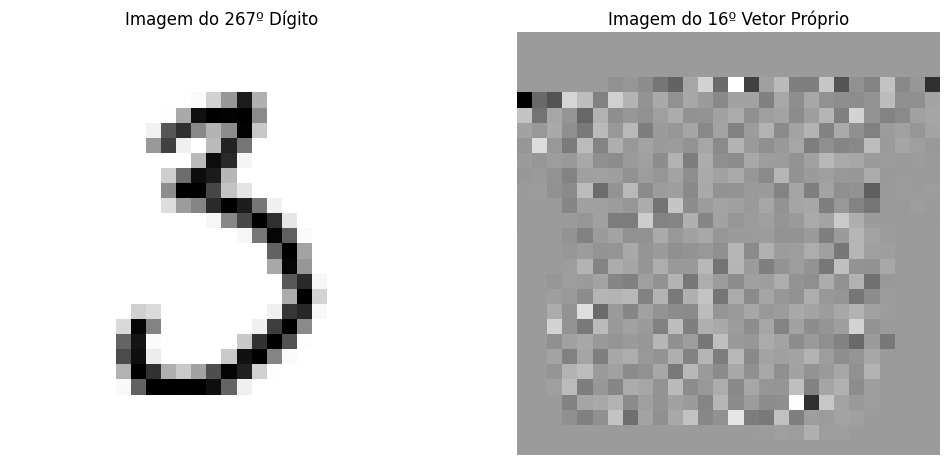

In [24]:
# Visualizar o 267º dígito do conjunto

digit_index = 266  # O 267º dígito
digit_image = X_3[:, digit_index].reshape(28, 28)

# Calcular a matriz de covariância e obter os vetores próprios
cov_matrix = np.cov(X_3)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Visualizar o 16º vetor próprio
eigenvector_index = 15  
eigenvector_image = eigenvectors[:, eigenvector_index].reshape(28, 28)

plt.figure(figsize=(12, 6))

# Imagem do 267º dígito
plt.subplot(1, 2, 1)
plt.title("Imagem do 267º Dígito")
plt.imshow(digit_image, cmap='binary')
plt.axis('off')

# Imagem do 16º vetor próprio
plt.subplot(1, 2, 2)
plt.title("Imagem do 16º Vetor Próprio")
plt.imshow(eigenvector_image, cmap='gray')
plt.axis('off')

plt.show()


# d.

#### Pretende-se projetar os digitos nas suas componentes principais. O numero minimo de componentes principias para que os dados projetados tenham acima de 65% da variancia total dos dados originais, é:

In [29]:
# Calcula a matriz de covariância dos dados X_3
cov = np.cov(X_3)

# Calcula os autovalores (u) e autovetores (W) da matriz de covariância
u, W = np.linalg.eig(cov)

u = u.real
W = W.real

# Ordena os autovalores em ordem decrescente e rearranja os autovetores de acordo
idx = np.argsort(-u)
u = u[idx]
W = W[:, idx]

un = u / np.sum(u)

# Calcula a variância explicada acumulada
L = np.cumsum(un)

# Encontrar o número mínimo de componentes para ter mais de 65% da variância
num_components = np.argmax(L > 0.65) + 1  
# Adicionar 1 porque a indexação começa em 0

print(f"Resposta: {num_components}")

Resposta: 15


# e.

#### O número de pixeis com valor igual a zero para todos os exemplos deste conjunto  ́e:

In [30]:
# Determinar os pixels com valor zero em todos os 372 exemplos
pixels_zero_all = np.all(X_3 == 0, axis=1)

# Contar o número de pixels que são zero em todos os exemplos
num_pixels_zero_all = np.sum(pixels_zero_all)

print(f"Resposta: {num_pixels_zero_all}")

Resposta: 283


# f.

#### Para esta alínea, arredonde os valores pedidos a 0 casas decimais.

##### i. A norma do vetor de média dos dados ́e 914.
##### ii. O desvio padrão da dimensão 363 dos dados ́e 0.

In [31]:
# Calcular a média dos dados e a norma do vetor de média
mean_vector = np.mean(X_3, axis=1)
norm_mean_vector = np.linalg.norm(mean_vector)

# Calcular o desvio padrão da dimensão 363 (no índice 362, pois a indexação começa em 0)
std_dev_dimension_363 = np.std(X_3[362, :])

# Exibir os resultados
print(f"Resposta i: {round(norm_mean_vector)}")
print(f"Resposta ii: {round(std_dev_dimension_363)}")


Resposta i: 1828
Resposta ii: 0
